In [1]:
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
CURRENT_YEAR = 2026   # used for car year age

In [2]:

from pathlib import Path
if not Path("train.csv").exists():
    from google.colab import files
    up = files.upload()
    Path(next(iter(up))).rename("train.csv")

raw = pd.read_csv("train.csv", index_col=0)
raw.index.name = "Car_ID"
print(raw.shape)
raw.head()

(5847, 13)


,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
Car_ID,,,,,,,,,,,,,
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,13 km/kg,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74
6,Nissan Micra Diesel XV,Jaipur,2013,86999,Diesel,Manual,First,23.08 kmpl,1461 CC,63.1 bhp,5.0,NaN,3.50


In [3]:
raw.info()
df = raw.copy()
missing = df.isna().sum()

summary = pd.DataFrame({"missing": missing, "pct": (df.isna().mean() * 100).round(1)})
print(summary[summary["missing"] > 0].sort_values("pct", ascending=False))

<class 'pandas.core.frame.DataFrame'>
Index: 5847 entries, 1 to 6018
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               5847 non-null   object 
 1   Location           5847 non-null   object 
 2   Year               5847 non-null   int64  
 3   Kilometers_Driven  5847 non-null   int64  
 4   Fuel_Type          5847 non-null   object 
 5   Transmission       5847 non-null   object 
 6   Owner_Type         5847 non-null   object 
 7   Mileage            5845 non-null   object 
 8   Engine             5811 non-null   object 
 9   Power              5811 non-null   object 
 10  Seats              5809 non-null   float64
 11  New_Price          815 non-null    object 
 12  Price              5847 non-null   float64
dtypes: float64(2), int64(2), object(9)
memory usage: 639.5+ KB
           missing   pct
New_Price     5032  86.1
Power           36   0.6
Engine          36   0.6
Seats         

In [4]:
#check if missing is overlapping, so dropping will only cost 0.6%
#of data
raw[["Power","Engine","Seats"]].isna().any(axis=1).sum()

np.int64(38)

In [5]:
df = df.drop(columns=["New_Price"])
df = df.dropna(subset=["Power", "Engine", "Seats", "Mileage"])

Dropped the column New_Price as it is 86.1% missing. We will not impute that much data.

Droppped rows since overlap would only result in a dropping of 0.6% of data cost, and will prevent creating 0.6% cars with created data in 3 features.

In [6]:
for col in ["Mileage", "Engine", "Power"]:
    print(col, raw[col].dropna().str.split().str[-1].value_counts().to_dict())

Mileage {'kmpl': 5842, 'km/kg': 3}
Engine {'CC': 5811}
Power {'bhp': 5811}


In [7]:
raw[raw["Mileage"].str.contains("km/kg", na=False)][["Name", "Fuel_Type", "Mileage"]]

,Name,Fuel_Type,Mileage
Car_ID,,,
2,Honda Jazz V,Petrol,13 km/kg
26,Nissan Micra Diesel XV,Diesel,16.48 km/kg
58,Nissan X-Trail SLX AT,Diesel,9.49 km/kg


In [8]:
kmkg_ids = raw.index[raw["Mileage"].str.contains("km/kg", na=False)]
df = df.drop(index=kmkg_ids, errors="ignore")
print(len(df))

5804


The unit audit showed Engine is all CC and Power is all bhp, but Mileage contains 3 in km/kg. Since km/kg measures distance per kilogram of fuel and isn’t comparable with km per litre, I dropped those 3 rows (0.05%) before removing units.

In [9]:
for col in ["Mileage", "Engine", "Power"]:
    df[col] = pd.to_numeric(df[col].str.split().str[0], errors="coerce")

In [10]:
print(df[["Mileage", "Engine", "Power"]].dtypes)
display(df[["Mileage", "Engine", "Power"]].head())

Mileage    float64
Engine       int64
Power      float64
dtype: object


,Mileage,Engine,Power
Car_ID,,,
1,19.67,1582,126.20
3,20.77,1248,88.76
4,15.20,1968,140.80
6,23.08,1461,63.10
7,11.36,2755,171.50


In [11]:
df[["Mileage", "Engine", "Power"]].dtypes
df[["Mileage", "Engine", "Power"]].head()
df.isna().sum()

,0
Name,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,0
Engine,0
Power,0


In [12]:
print(df["Fuel_Type"].value_counts())
print(df["Transmission"].value_counts())

Fuel_Type
Diesel    3150
Petrol    2654
Name: count, dtype: int64
Transmission
Manual       4103
Automatic    1701
Name: count, dtype: int64


In [13]:
df = pd.get_dummies(df, columns=["Fuel_Type", "Transmission"], dtype=int)
df.head()

,Name,Location,Year,Kilometers_Driven,Owner_Type,Mileage,Engine,Power,Seats,Price,Fuel_Type_Diesel,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual
Car_ID,,,,,,,,,,,,,,
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,First,19.67,1582,126.20,5.0,12.50,1,0,0,1
3,Maruti Ertiga VDI,Chennai,2012,87000,First,20.77,1248,88.76,7.0,6.00,1,0,0,1
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Second,15.20,1968,140.80,5.0,17.74,1,0,1,0
6,Nissan Micra Diesel XV,Jaipur,2013,86999,First,23.08,1461,63.10,5.0,3.50,1,0,0,1
7,Toyota Innova Crysta 2.8 GX AT 8S,Mumbai,2016,36000,First,11.36,2755,171.50,8.0,17.50,1,0,1,0


Encoded Fuel_Type (Diesel, Petrol) and Transmission (Automatic, Manual) with pd.get_dummies. With only two levels each, it only adds a net of 2 columns


In [14]:
df["Car_Age"] = CURRENT_YEAR - df["Year"]
df[["Year", "Car_Age"]].head()

,Year,Car_Age
Car_ID,,
1,2015,11
3,2012,14
4,2013,13
6,2013,13
7,2016,10


Created Car_Age = 2026 - Year, the age of each car in years.

In [15]:
#select
df[["Name", "Year", "Car_Age", "Price"]].head()

,Name,Year,Car_Age,Price
Car_ID,,,,
1,Hyundai Creta 1.6 CRDi SX Option,2015,11,12.50
3,Maruti Ertiga VDI,2012,14,6.00
4,Audi A4 New 2.0 TDI Multitronic,2013,13,17.74
6,Nissan Micra Diesel XV,2013,13,3.50
7,Toyota Innova Crysta 2.8 GX AT 8S,2016,10,17.50


In [16]:
#filter
df[df["Car_Age"] <= 10].head()

,Name,Location,Year,Kilometers_Driven,Owner_Type,Mileage,Engine,Power,Seats,Price,Fuel_Type_Diesel,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual,Car_Age
Car_ID,,,,,,,,,,,,,,,
7,Toyota Innova Crysta 2.8 GX AT 8S,Mumbai,2016,36000,First,11.36,2755,171.50,8.0,17.50,1,0,1,0,10
10,Maruti Ciaz Zeta,Kochi,2018,25692,First,21.56,1462,103.25,5.0,9.95,0,1,0,1,8
16,Honda Amaze S i-Dtech,Kochi,2016,58950,First,25.80,1498,98.60,5.0,5.40,1,0,0,1,10
17,Maruti Swift DDiS VDI,Jaipur,2017,25000,First,28.40,1248,74.00,5.0,5.99,1,0,0,1,9
28,Honda WRV i-VTEC VX,Kochi,2018,37430,First,17.50,1199,88.70,5.0,9.90,0,1,0,1,8


In [17]:
#rename
df.rename(columns={"Kilometers_Driven": "Km_Driven"}).head()

,Name,Location,Year,Km_Driven,Owner_Type,Mileage,Engine,Power,Seats,Price,Fuel_Type_Diesel,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual,Car_Age
Car_ID,,,,,,,,,,,,,,,
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,First,19.67,1582,126.20,5.0,12.50,1,0,0,1,11
3,Maruti Ertiga VDI,Chennai,2012,87000,First,20.77,1248,88.76,7.0,6.00,1,0,0,1,14
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Second,15.20,1968,140.80,5.0,17.74,1,0,1,0,13
6,Nissan Micra Diesel XV,Jaipur,2013,86999,First,23.08,1461,63.10,5.0,3.50,1,0,0,1,13
7,Toyota Innova Crysta 2.8 GX AT 8S,Mumbai,2016,36000,First,11.36,2755,171.50,8.0,17.50,1,0,1,0,10


In [18]:
#mutate
df.assign(Mileage_per_bhp=df["Mileage"] / df["Power"]).head()

,Name,Location,Year,Kilometers_Driven,Owner_Type,Mileage,Engine,Power,Seats,Price,Fuel_Type_Diesel,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual,Car_Age,Mileage_per_bhp
Car_ID,,,,,,,,,,,,,,,,
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,First,19.67,1582,126.20,5.0,12.50,1,0,0,1,11,0.155864
3,Maruti Ertiga VDI,Chennai,2012,87000,First,20.77,1248,88.76,7.0,6.00,1,0,0,1,14,0.234002
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Second,15.20,1968,140.80,5.0,17.74,1,0,1,0,13,0.107955
6,Nissan Micra Diesel XV,Jaipur,2013,86999,First,23.08,1461,63.10,5.0,3.50,1,0,0,1,13,0.365769
7,Toyota Innova Crysta 2.8 GX AT 8S,Mumbai,2016,36000,First,11.36,2755,171.50,8.0,17.50,1,0,1,0,10,0.066239


In [19]:
#arrange
df.sort_values("Price", ascending=False).head()

,Name,Location,Year,Kilometers_Driven,Owner_Type,Mileage,Engine,Power,Seats,Price,Fuel_Type_Diesel,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual,Car_Age
Car_ID,,,,,,,,,,,,,,,
4079,Land Rover Range Rover 3.0 Diesel LWB Vogue,Hyderabad,2017,25000,First,13.33,2993,255.0,5.0,160.00,1,0,1,0,9
5781,Lamborghini Gallardo Coupe,Delhi,2011,6500,Third,6.40,5204,560.0,2.0,120.00,0,1,1,0,15
5919,Jaguar F Type 5.0 V8 S,Hyderabad,2015,8000,First,12.50,5000,488.1,2.0,100.00,0,1,1,0,11
1505,Land Rover Range Rover Sport SE,Kochi,2019,26013,First,12.65,2993,255.0,5.0,97.07,1,0,1,0,7
1974,BMW 7 Series 740Li,Coimbatore,2018,28060,First,12.05,2979,320.0,5.0,93.67,0,1,1,0,8


In [20]:
#group by
df.groupby("Owner_Type")["Price"].agg(["count", "mean", "median"])

,count,mean,median
Owner_Type,,,
First,4783,10.125800,6.00
Fourth & Above,7,3.567143,3.25
Second,913,7.847952,4.50
Third,101,5.299505,2.95


Q2

In [21]:
if not Path("diabetes.csv").exists():
  from google.colab import files  # upload widget
  files.upload()  # pick diabetes.csv

Saving diabetes.csv to diabetes.csv


In [22]:
pop = pd.read_csv("diabetes.csv")
print(pop.shape)
pop.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [23]:
sample = pop.sample(n=25, random_state=42)
glucose = pd.DataFrame({"sample": [sample["Glucose"].mean(), sample["Glucose"].max()], "population": [pop["Glucose"].mean(), pop["Glucose"].max()]}, index=["mean", "max"])
glucose["difference"] = glucose["sample"] - glucose["population"]
glucose

,sample,population,difference
mean,116.64,120.894531,-4.254531
max,183.00,199.000000,-16.000000


<Axes: title={'center': 'Glucose: sample vs population'}>

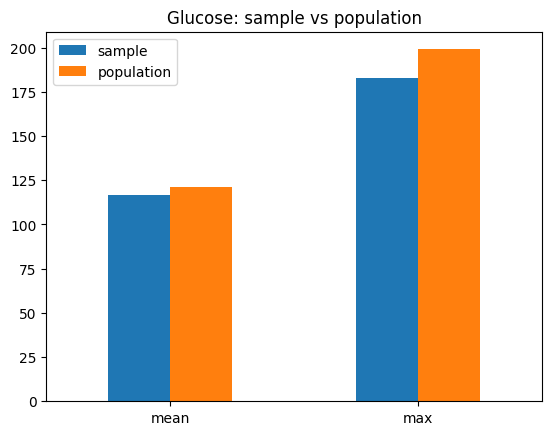

In [24]:
glucose[["sample", "population"]].plot.bar(title="Glucose: sample vs population", rot=0)

The sample mean estimates the population mean. The sample max can never be higher than the population max, so it is usually lower, because one small sample rarely contains the most extreme patient.

In [25]:
bmi = pd.DataFrame({"sample": [sample["BMI"].quantile(0.98)], "population": [pop["BMI"].quantile(0.98)]}, index=["98th percentile"])
bmi["difference"] = bmi["sample"] - bmi["population"]
bmi

,sample,population,difference
98th percentile,40.248,47.526,-7.278


<Axes: title={'center': 'BMI 98th percentile: sample vs population'}>

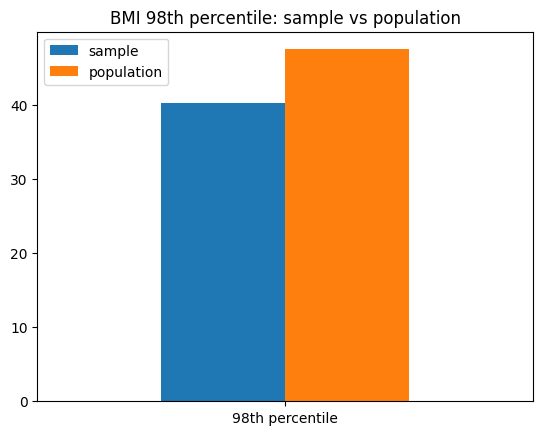

In [26]:
bmi[["sample", "population"]].plot.bar(title="BMI 98th percentile: sample vs population", rot=0)

In [27]:
np.random.seed(42)  # seed so the bootstrap is reproducible
rows = []
for i in range(500):
    s = pop["BloodPressure"].sample(n=150, replace=True)
    rows.append([s.mean(), s.std(), s.quantile(0.98)])

In [28]:
boot = pd.DataFrame(rows, columns=["mean", "std", "p98"])
boot.head()

,mean,std,p98
0,71.160000,16.061158,100.00
1,70.980000,15.486938,104.04
2,71.133333,15.138584,106.00
3,69.566667,18.782906,96.08
4,65.986667,22.750466,95.18


In [29]:
comparison = pd.DataFrame({"bootstrap average": boot.mean(), "population": [pop["BloodPressure"].mean(), pop["BloodPressure"].std(), pop["BloodPressure"].quantile(0.98)]})
comparison["difference"] = comparison["bootstrap average"] - comparison["population"]
comparison

,bootstrap average,population,difference
mean,69.176920,69.105469,0.071451
std,19.073718,19.355807,-0.282089
p98,97.902440,99.320000,-1.417560


<Axes: title={'center': 'BloodPressure: bootstrap average vs population'}>

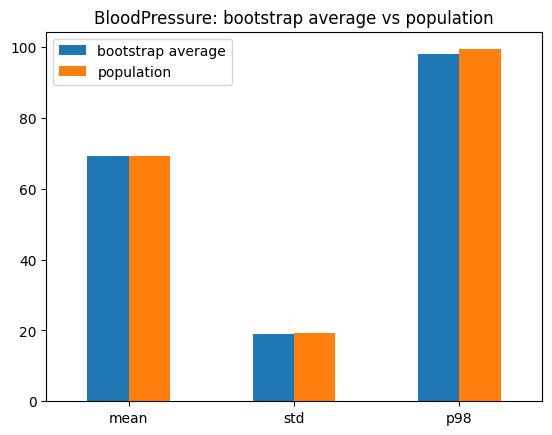

In [30]:
comparison[["bootstrap average", "population"]].plot.bar(title="BloodPressure: bootstrap average vs population", rot=0)

Findings: The bootstrap average of the mean is almost the same as the population mean (see the difference column). The bootstrap std and 98th percentile differ a little more from the population values, because each sample of 150 has only a few values in that far into the extreme tail. So bootstrap means estimate the population mean well, while extreme/close to outlier percentiles are less common or stable.